<a href="https://colab.research.google.com/github/ChristZ-coderFs/ITC3154-Customer-Churn/blob/christos-data/Christos_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Dataset Loading and Initial Exploration, Christos Zotos**



In [6]:
import pandas as pd

df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.shape)
print(df.head())

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [7]:
print(df.info())

print(df.describe())

print(df['Churn'].value_counts())

print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# Data Quality and Missing Values

In [8]:
# convert TotalCharges to numeric values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# check missing values
print(df.isnull().sum())

print("\nTotalCharges statistics:")
print(df['TotalCharges'].describe())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

TotalCharges statistics:
count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64


In [9]:
print(df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No


# Exploratory Data Visualizations

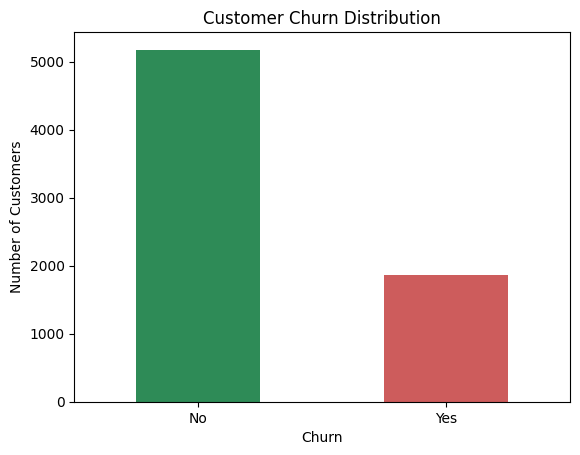

In [10]:
import matplotlib.pyplot as plt

df['Churn'].value_counts().plot(kind='bar', color=['seagreen', 'indianred'])

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


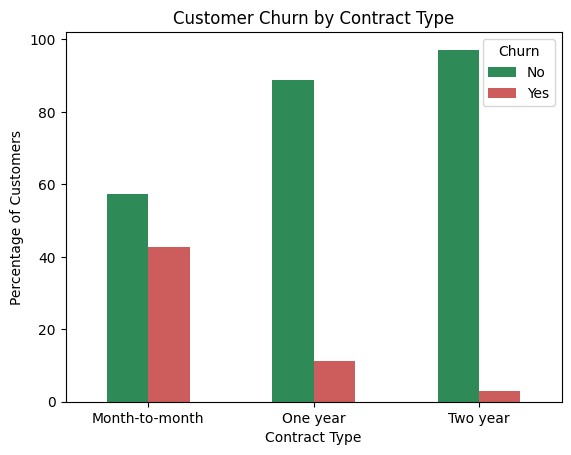

In [11]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

print(contract_churn.round(2))
contract_churn.plot(kind='bar', color=['seagreen', 'indianred'])
plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.show()

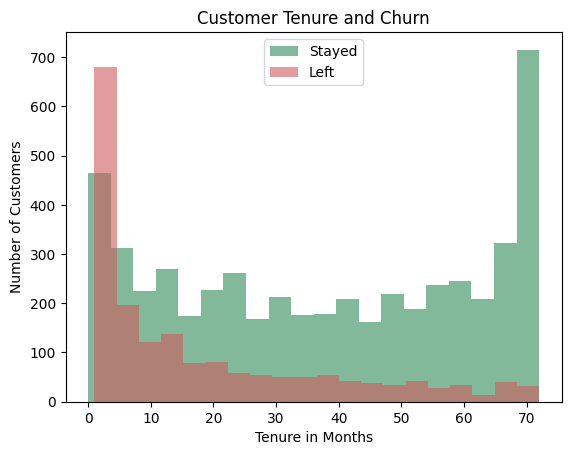

In [12]:
plt.hist(df[df['Churn'] == 'No']['tenure'], bins=20,
         color='seagreen', alpha=0.6, label='Stayed')

plt.hist(df[df['Churn'] == 'Yes']['tenure'], bins=20,
         color='indianred', alpha=0.6, label='Left')

plt.title('Customer Tenure and Churn')
plt.xlabel('Tenure in Months')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

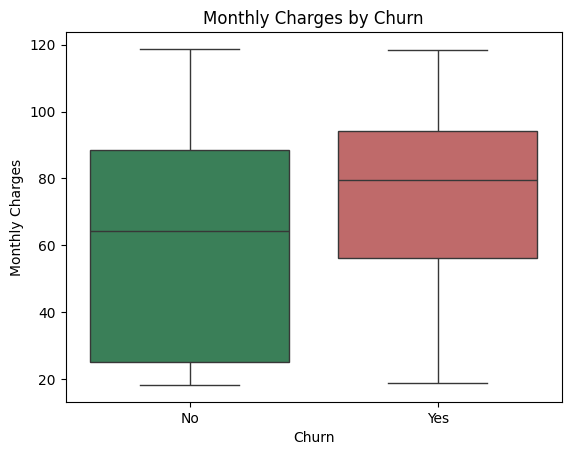

In [13]:
import seaborn as sns

sns.boxplot(data=df, x='Churn', y='MonthlyCharges',
            hue='Churn', palette=['seagreen', 'indianred'],
            legend=False)
plt.title('Monthly Charges by Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

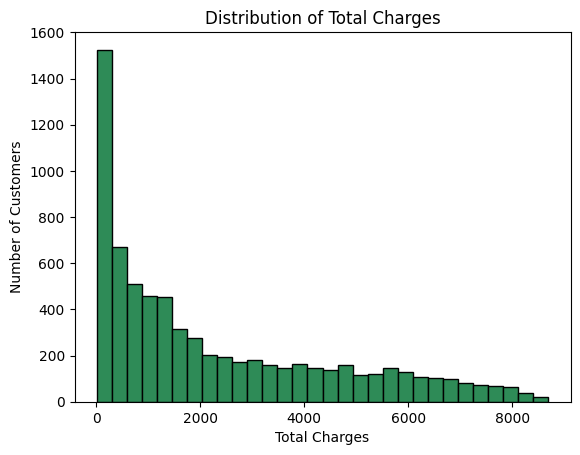

In [14]:
plt.hist(df['TotalCharges'].dropna(), bins=30, color='seagreen',
         edgecolor='black')
plt.title('Distribution of Total Charges')
plt.xlabel('Total Charges')
plt.ylabel('Number of Customers')
plt.show()

# Correlation Analysis and Feature Selection

                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
SeniorCitizen            1.00    0.02            0.22          0.10
tenure                   0.02    1.00            0.25          0.83
MonthlyCharges           0.22    0.25            1.00          0.65
TotalCharges             0.10    0.83            0.65          1.00


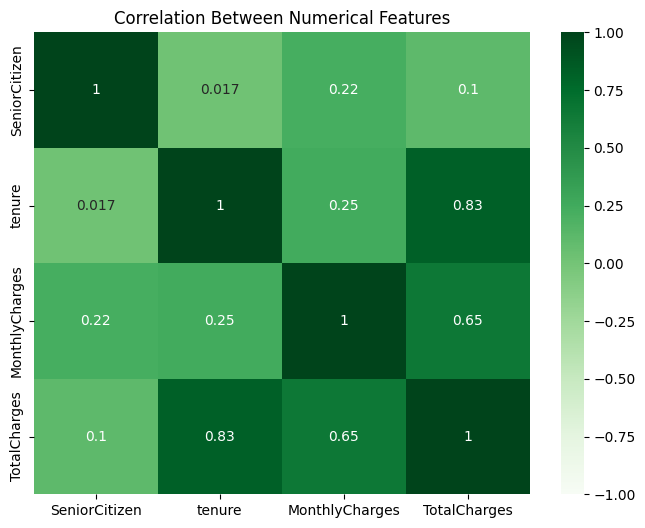

In [15]:
numeric_data = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']]

correlation = numeric_data.corr()
print(correlation.round(2))
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='Greens', vmin=-1, vmax=1)
plt.title('Correlation Between Numerical Features')
plt.show()

In [16]:
print(df.nunique())

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6530
Churn                  2
dtype: int64


In [17]:
print("Unique customer IDs:", df['customerID'].nunique())
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

Unique customer IDs: 7043
Duplicate customer IDs: 0


# Data Cleaning and Preprocessing

In [18]:
missing = df[df['TotalCharges'].isnull()]
print(missing[['tenure', 'MonthlyCharges', 'TotalCharges']])

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


In [19]:
data = df.drop('customerID', axis=1)
print(data.shape)
print(data.head())

(7043, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes   

In [20]:
data['TotalCharges'] = data['TotalCharges'].fillna(0)
print("Remaining missing values:")
print(data.isnull().sum())

Remaining missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [21]:
data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})
print(data['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [22]:
print("Dataset shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate original rows:", df.duplicated().sum())
print(data.head())

Dataset shape: (7043, 20)
Missing values: 0
Duplicate original rows: 0
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No         

# Dataset Splitting

In [23]:
X = data.drop('Churn', axis=1)
y = data['Churn']
print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 19)
Target: (7043,)


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

In [25]:
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation churn distribution:")
print(y_val.value_counts(normalize=True))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True))

Training set: (4930, 19)
Validation set: (1056, 19)
Testing set: (1057, 19)

Training churn distribution:
Churn
0    0.734686
1    0.265314
Name: proportion, dtype: float64

Validation churn distribution:
Churn
0    0.734848
1    0.265152
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    0.734153
1    0.265847
Name: proportion, dtype: float64


# Categorical Feature Encoding

In [26]:
categorical_columns = X_train.select_dtypes(include='object').columns

print("Categorical features:")
print(categorical_columns)

print("\nNumber of categorical features:", len(categorical_columns))

Categorical features:
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

Number of categorical features: 15


In [27]:
X_train_encoded = pd.get_dummies(X_train, dtype=int)
X_val_encoded = pd.get_dummies(X_val, dtype=int)
X_test_encoded = pd.get_dummies(X_test, dtype=int)

In [28]:
X_val_encoded = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

In [29]:
print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Testing:", X_test_encoded.shape)
print(X_train_encoded.head())

Training: (4930, 45)
Validation: (1056, 45)
Testing: (1057, 45)
      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Female  \
5557              0       5           80.20        384.25              1   
2270              1       3           86.85        220.95              1   
6930              0       3           75.15        216.75              1   
2257              0      60           80.55       4847.05              1   
898               0      12           98.90       1120.95              1   

      gender_Male  Partner_No  Partner_Yes  Dependents_No  Dependents_Yes  \
5557            0           1            0              1               0   
2270            0           1            0              1               0   
6930            0           0            1              1               0   
2257            0           1            0              1               0   
898             0           1            0              1               0   

      ...  Strea

# Numerical Feature Standardization

In [30]:
from sklearn.preprocessing import StandardScaler

numerical_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X_train_encoded[numerical_columns] = scaler.fit_transform(X_train_encoded[numerical_columns])
X_val_encoded[numerical_columns] = scaler.transform(X_val_encoded[numerical_columns])
X_test_encoded[numerical_columns] = scaler.transform(X_test_encoded[numerical_columns])

In [31]:
print("Standardized numerical features:")
print(X_train_encoded[numerical_columns].head())

print("\nMean:")
print(X_train_encoded[numerical_columns].mean().round(4))

print("\nStandard deviation:")
print(X_train_encoded[numerical_columns].std(ddof=0).round(4))

Standardized numerical features:
        tenure  MonthlyCharges  TotalCharges
5557 -1.114728        0.504286     -0.836504
2270 -1.195884        0.724189     -0.907742
6930 -1.195884        0.337292     -0.909574
2257  1.117066        0.515860      1.110332
898  -0.830682        1.122660     -0.515129

Mean:
tenure            0.0
MonthlyCharges    0.0
TotalCharges     -0.0
dtype: float64

Standard deviation:
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
dtype: float64


In [33]:
print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Testing:", X_test_encoded.shape)

print("Missing training values:", X_train_encoded.isnull().sum().sum())
print("Missing validation values:", X_val_encoded.isnull().sum().sum())
print("Missing testing values:", X_test_encoded.isnull().sum().sum())

Training: (4930, 45)
Validation: (1056, 45)
Testing: (1057, 45)
Missing training values: 0
Missing validation values: 0
Missing testing values: 0


# Exporting the Prepared Datasets

In [34]:
train_data = X_train_encoded.copy()
val_data = X_val_encoded.copy()
test_data = X_test_encoded.copy()

train_data['Churn'] = y_train
val_data['Churn'] = y_val
test_data['Churn'] = y_test

In [35]:
train_data.to_csv('churn_train.csv', index=False)
val_data.to_csv('churn_validation.csv', index=False)
test_data.to_csv('churn_test.csv', index=False)